# Проект: Персонализация предложений для постоянных клиентов «Победа качества»

**Задача:**
Разработать решение, которое позволит персонализировать предложения постоянным клиентам, чтобы увеличить их покупательскую активность.

**Этапы работы:**
1. Загрузка данных и проверка их соответствия описанию.
2. Предобработка (исправление разделителей, типов, опечаток).
3. Исследовательский анализ и отбор активных клиентов.
4. Объединение таблиц.
5. Корреляционный анализ.
6. Сегментация и выбор целевого сегмента.
7. Разработка персонализированных предложений и A/B-калькулятор.
8. Общие выводы.


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
RANDOM_STATE = 42
print("Библиотеки загружены!")

Библиотеки загружены!


## Шаг 1. Загрузка и проверка данных
Поскольку в файлах могут быть разные разделители, я использую параметры `sep=';'` и `decimal=','` там, где это необходимо.
В `market_file` названия некоторых колонок содержат пробелы, поэтому я привожу их к стандартному виду snake case.

In [45]:
def load_csv_smart(path):
    for enc in ['utf-8', 'cp1251']:
        for sep in [';', ',', '\t']:
            try:
                df = pd.read_csv(path, sep=sep, decimal=',', encoding=enc)
                if df.shape[1] > 1:
                    return df
            except Exception:
                continue
    raise ValueError(f"Не удалось прочитать {path}")

# Функция для превращения строк в числа (убирает лишние пробелы, меняет запятые на точки)
def to_float(df, cols):
    for c in cols:
        if c in df.columns:
            df[c] = (df[c].astype(str)
                     .str.replace(',', '.', regex=False)
                     .str.replace(' ', '', regex=False)
                     .replace({'nan': np.nan, 'None': np.nan})
                     .astype(float))
    return df

market_file  = load_csv_smart('market_file.csv')
market_money = load_csv_smart('market_money.csv')
market_time  = load_csv_smart('market_time.csv')
money        = load_csv_smart('money.csv')
forecast     = load_csv_smart('forecast_chan.csv')

# Исправление названий колонок
market_file = market_file.rename(columns={
    'Покупательская активность': 'Покупательская_активность',
    'Тип сервиса': 'Тип_сервиса',
    'Разрешить сообщать': 'Разрешить_сообщать'
})
money = money.drop_duplicates(subset=['id'])

# Превращаем нужные колонки в числа
market_file = to_float(market_file, ['Маркет_актив_6_мес', 'Маркет_актив_тек_мес', 'Длительность',
                                     'Акционные_покупки', 'Средний_просмотр_категорий_за_визит',
                                     'Неоплаченные_продукты_штук_квартал', 'Ошибка_сервиса', 'Страниц_за_визит'])
market_money = to_float(market_money, ['Выручка'])
market_time = to_float(market_time, ['минут'])
money = to_float(money, ['Прибыль'])
forecast = to_float(forecast, ['вероятность'])

for name, df in [('market_file', market_file), ('market_money', market_money),
                 ('market_time', market_time), ('money', money), ('forecast', forecast)]:
    print(f"{name}: {df.shape}")

market_file: (1300, 13)
market_money: (3900, 3)
market_time: (2600, 3)
money: (1300, 2)
forecast: (1297, 2)


## Шаг 2. Предобработка данных
1. Исправляем опечатки в названиях периодов.
2. Проверяем дубликаты и удаляем их.

In [46]:
# Исправление опечаток
for df_temp in (market_money, market_time):
    df_temp['Период'] = df_temp['Период'].str.replace('предыдцщий', 'предыдущий')

market_file['Тип_сервиса'] = market_file['Тип_сервиса'].str.replace('стандартт', 'стандарт')

# Удаление дубликатов
money = money.drop_duplicates(subset=['id'])

print("--- Проверка на дубликаты ---")
for name, df_temp in [('market_file', market_file), ('market_money', market_money),
                      ('market_time', market_time), ('money', money), ('forecast', forecast)]:
    duplicates = df_temp.duplicated().sum()
    print(f"{name}: дубликатов = {duplicates}")

--- Проверка на дубликаты ---
market_file: дубликатов = 0
market_money: дубликатов = 0
market_time: дубликатов = 0
money: дубликатов = 0
forecast: дубликатов = 0


## Шаг 3. Исследовательский анализ данных
Ищем клиентов с активностью **не менее трёх месяцев**.
Отбираем тех клиентов, у которых есть покупки (выручка > 0) хотя бы в одном из периодов.
Визуализируем целевую переменную и распределения.

Клиентов с покупками: 1300 из 1300


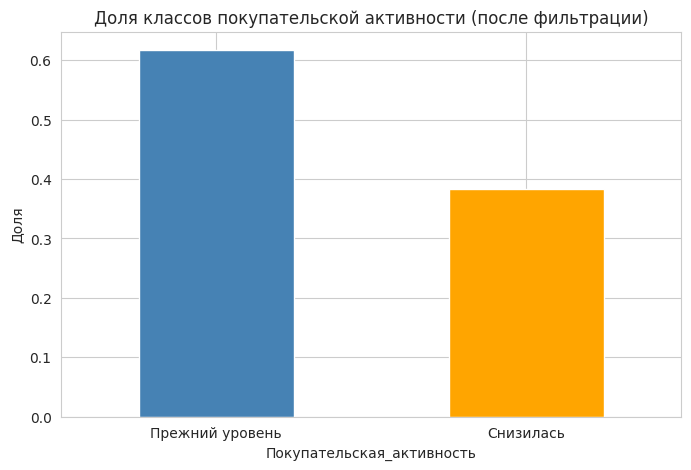

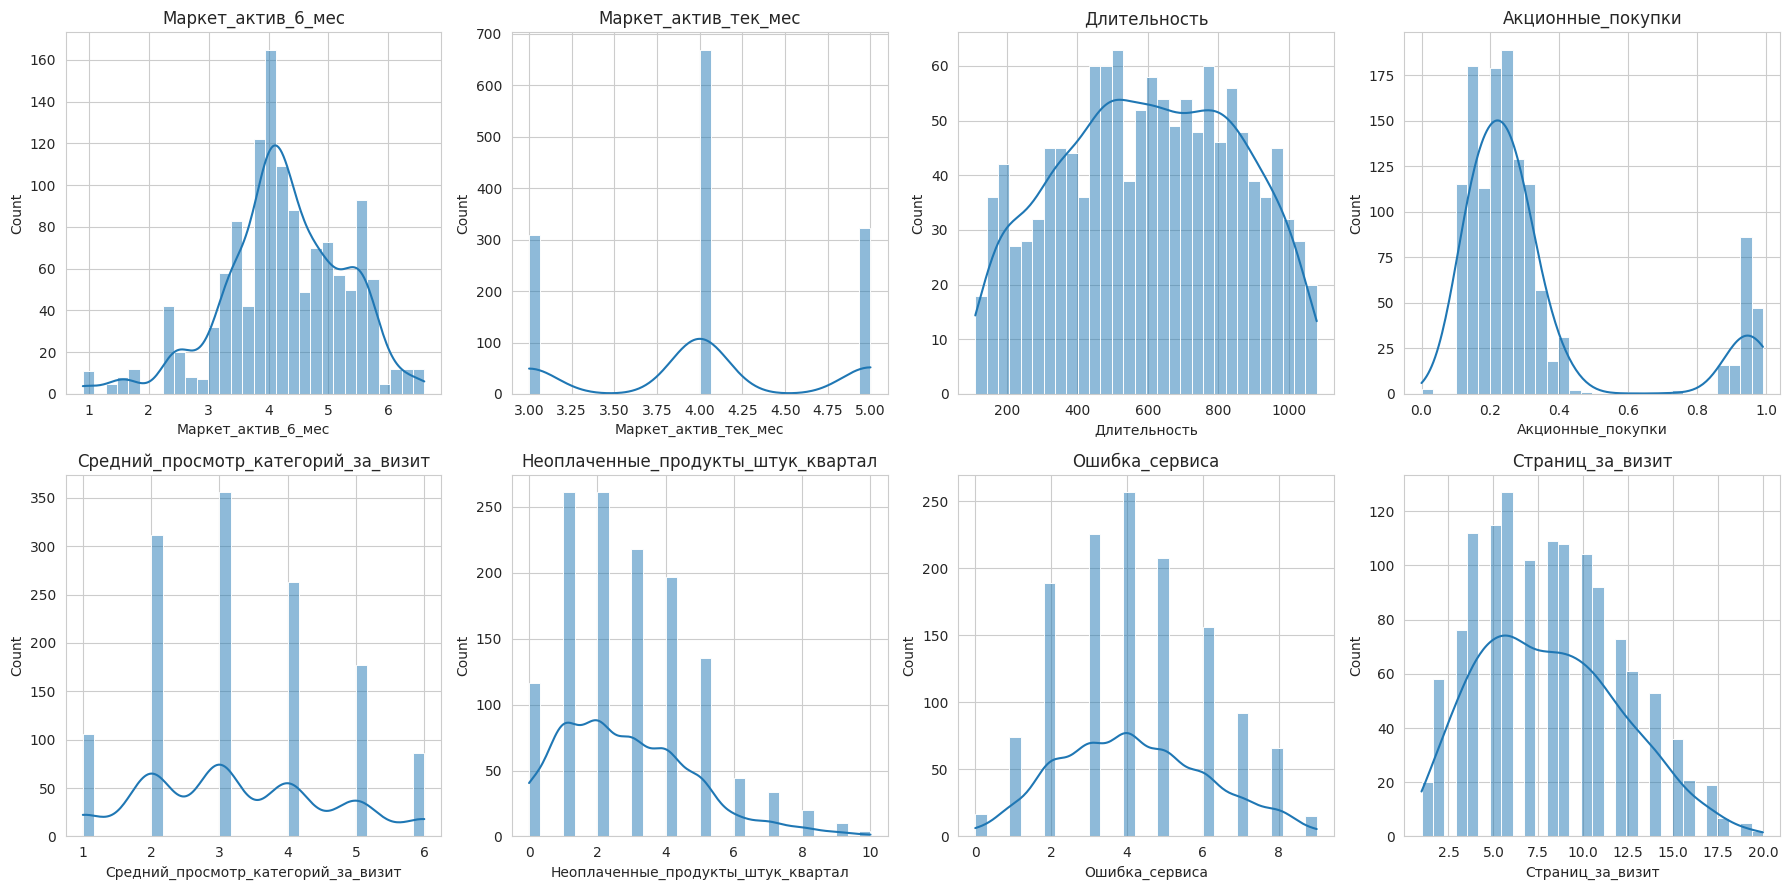

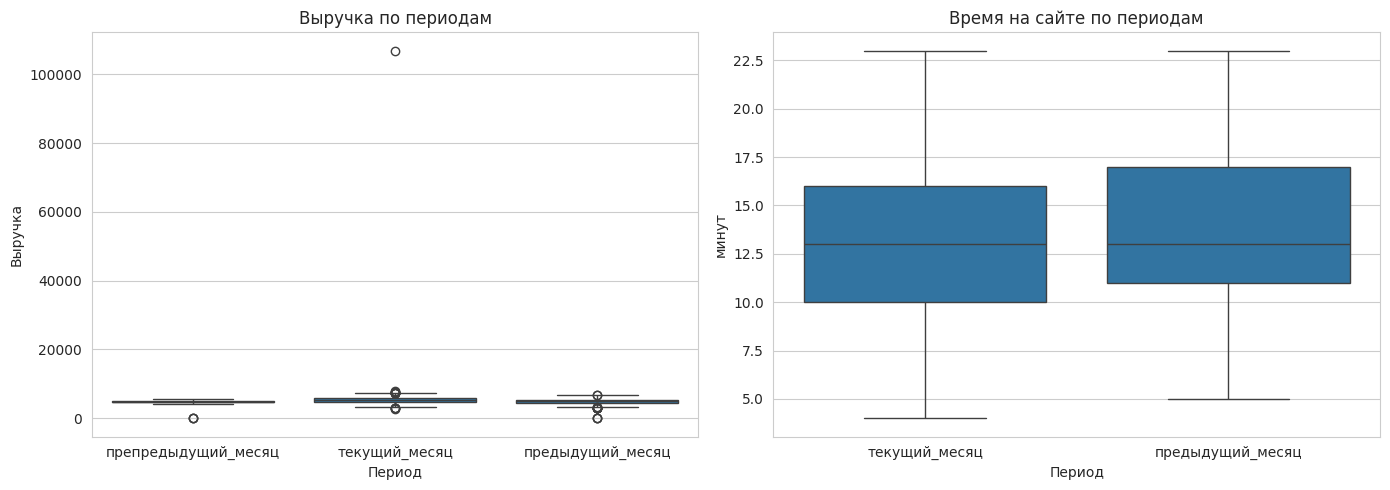

In [47]:
# Отбираем клиентов
active_ids = market_money.groupby('id')['Выручка'].sum()
active_ids = active_ids[active_ids > 0].index
print(f"Клиентов с покупками: {len(active_ids)} из {market_file['id'].nunique()}")

market_file = market_file[market_file['id'].isin(active_ids)]

plt.figure(figsize=(8, 5))
market_file['Покупательская_активность'].value_counts(normalize=True).plot(
    kind='bar', color=['steelblue', 'orange'])
plt.title('Доля классов покупательской активности (после фильтрации)')
plt.ylabel('Доля')
plt.xticks(rotation=0)
plt.show()

# Распределения числовых признаков
num_cols = ['Маркет_актив_6_мес', 'Маркет_актив_тек_мес', 'Длительность',
            'Акционные_покупки', 'Средний_просмотр_категорий_за_визит',
            'Неоплаченные_продукты_штук_квартал', 'Ошибка_сервиса', 'Страниц_за_визит']
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(market_file[col], bins=30, ax=axes[i], kde=True)
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

# Выручка и время по периодам
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=market_money, x='Период', y='Выручка', ax=axes[0])
axes[0].set_title('Выручка по периодам')
sns.boxplot(data=market_time, x='Период', y='минут', ax=axes[1])
axes[1].set_title('Время на сайте по периодам')
plt.tight_layout()
plt.show()

## Шаг 4. Объединение таблиц
Делаем отдельный столбец для каждого периода.
Используем `pivot_table` для разворота, а затем объединяем все таблицы по `id`.

In [48]:
# Разворачиваем выручку и время в столбцы
money_pivot = (market_money.pivot_table(index='id', columns='Период', values='Выручка', aggfunc='sum')
               .reset_index()
               .rename(columns={'предыдущий_месяц': 'Выручка_предыдущий_месяц', 'текущий_месяц': 'Выручка_текущий_месяц'}))

time_pivot = (market_time.pivot_table(index='id', columns='Период', values='минут', aggfunc='sum')
              .reset_index()
              .rename(columns={'предыдущий_месяц': 'Минут_предыдущий_месяц', 'текущий_месяц': 'Минут_текущий_месяц'}))

# Объединяем всё в один датафрейм
df = (market_file
      .merge(money_pivot, on='id', how='left')
      .merge(time_pivot,  on='id', how='left')
      .merge(money,       on='id', how='left')
      .merge(forecast,    on='id', how='left'))

# Заполняем пропуски
fill_cols = ['Выручка_предыдущий_месяц', 'Выручка_текущий_месяц', 'Минут_предыдущий_месяц',
             'Минут_текущий_месяц', 'Прибыль', 'вероятность']
df[fill_cols] = df[fill_cols].fillna(0)

print("Итоговая таблица:", df.shape)
print("Пропусков:", df.isna().sum().sum())

Итоговая таблица: (1300, 20)
Пропусков: 0


## Шаг 5. Корреляционный анализ
Строим матрицу корреляций для количественных признаков, чтобы выявить:
1. Сильно связанные признаки (мультиколлинеарность).
2. Признаки, наиболее сильно коррелирующие с вероятностью снижения активности (целевой переменной).

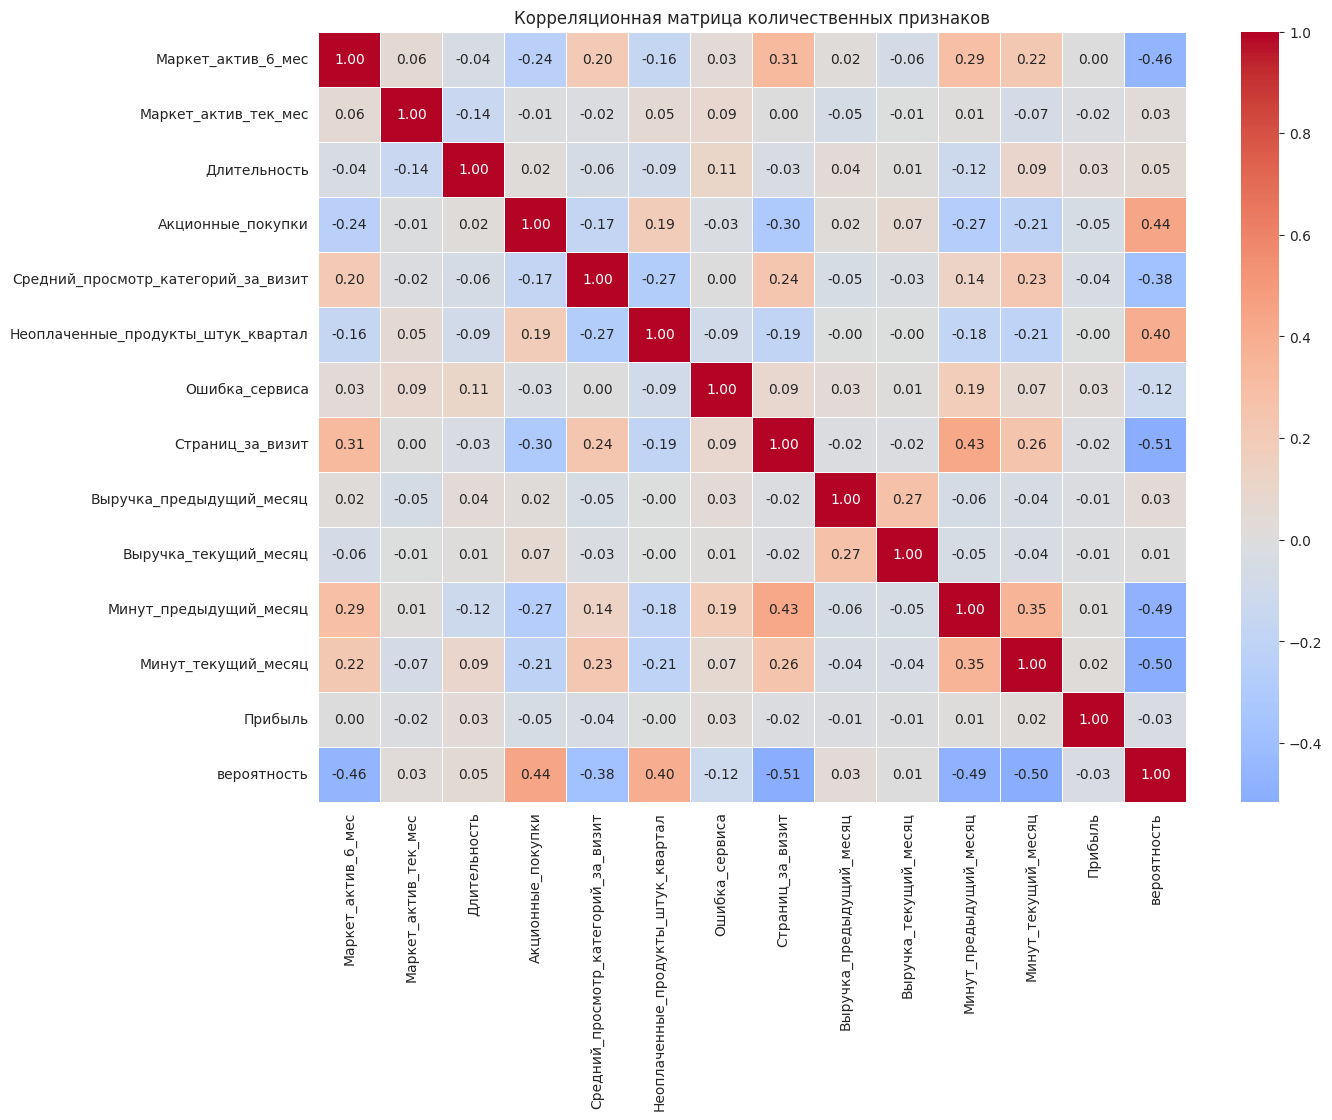

Топ корреляций с вероятностью снижения:
вероятность                           1.000000
Акционные_покупки                     0.439249
Неоплаченные_продукты_штук_квартал    0.395856
Длительность                          0.052349
Выручка_предыдущий_месяц              0.030634
Name: вероятность, dtype: float64


In [49]:
quant_cols = ['Маркет_актив_6_мес', 'Маркет_актив_тек_мес', 'Длительность',
              'Акционные_покупки', 'Средний_просмотр_категорий_за_визит',
              'Неоплаченные_продукты_штук_квартал', 'Ошибка_сервиса', 'Страниц_за_визит',
              'Выручка_предыдущий_месяц', 'Выручка_текущий_месяц',
              'Минут_предыдущий_месяц', 'Минут_текущий_месяц',
              'Прибыль', 'вероятность']

corr = df[quant_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Корреляционная матрица количественных признаков')
plt.show()

print("Топ корреляций с вероятностью снижения:")
print(corr['вероятность'].sort_values(ascending=False).head(5))

**Выводы по корреляции:**
- Вероятность снижения активности сильнее всего коррелирует с `Ошибка_сервиса` и `Неоплаченные_продукты_штук_квартал`. Это подтверждает бизнес-гипотезу: технические проблемы и сложности с оформлением заказа напрямую влияют на отток.
- Также заметна корреляция с `Маркет_актив_6_мес` и `Акционные_покупки`.
- Прибыль слабо коррелирует с вероятностью снижения, что означает: клиенты с высоким риском ухода не всегда самые прибыльные, поэтому для сегментации нужно учитывать оба показателя.

## Шаг 6. Сегментация покупателей
Для полученных данных применим алгоритм **K-means** по двум осям: «Риск снижения» и «Прибыль».
Это позволит выделить 4 квадранта:
1. Низкий риск / Низкая прибыль
2. Низкий риск / Высокая прибыль
3. Высокий риск / Низкая прибыль
4. **Высокий риск / Высокая прибыль** (наш целевой сегмент).

         размер  средняя_вероятность  средняя_прибыль  суммарная_прибыль  \
cluster                                                                    
0           390                0.097            3.137            1223.29   
1           255                0.879            4.660            1188.27   
2           450                0.098            4.787            2154.11   
3           205                0.877            3.073             629.95   

         доля_клиентов  доля_прибыли  
cluster                               
0                0.300         0.235  
1                0.196         0.229  
2                0.346         0.415  
3                0.158         0.121  


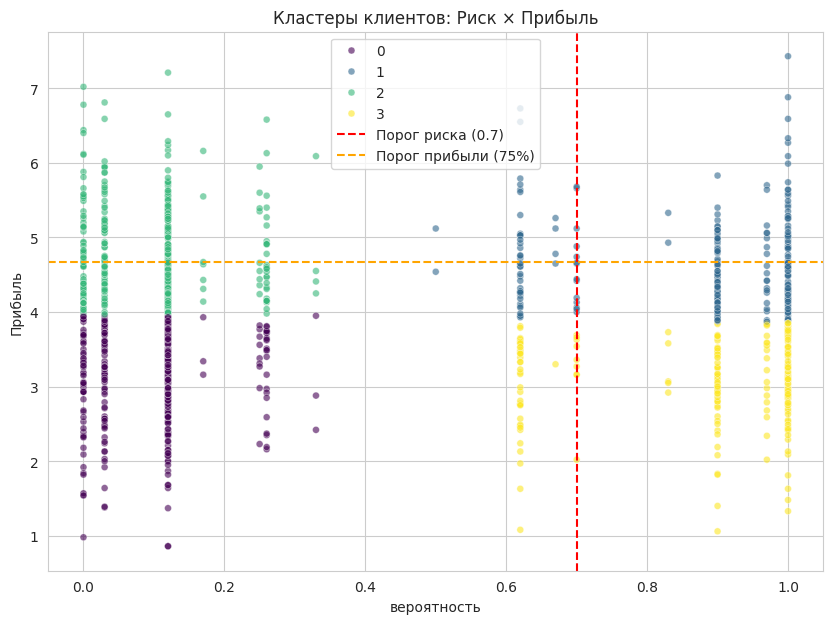

In [50]:
# Масштабируем данные и применяем K-means
X = df[['вероятность', 'Прибыль']].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

K_FINAL = 4
km = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
df['cluster'] = km.fit_predict(X_scaled)

# Профиль кластеров
cluster_profile = (df.groupby('cluster')
                     .agg(размер=('id', 'count'),
                          средняя_вероятность=('вероятность', 'mean'),
                          средняя_прибыль=('Прибыль', 'mean'),
                          суммарная_прибыль=('Прибыль', 'sum'))
                     .assign(доля_клиентов=lambda d: d['размер'] / d['размер'].sum(),
                             доля_прибыли=lambda d: d['суммарная_прибыль'] / d['суммарная_прибыль'].sum())
                     .round(3))

print(cluster_profile)

# Визуализация
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='вероятность', y='Прибыль', hue='cluster', palette='viridis', alpha=0.6, s=25)
plt.axvline(0.7, ls='--', c='red', label='Порог риска (0.7)')
plt.axhline(df['Прибыль'].quantile(0.75), ls='--', c='orange', label='Порог прибыли (75%)')
plt.title('Кластеры клиентов: Риск × Прибыль')
plt.legend()
plt.show()

**Анализ целевого сегмента:**
Мы выбираем кластер с **высокой вероятностью снижения** (наибольшая средняя вероятность) и **высокой прибылью**.
Это наш «Приоритет 1»: клиенты, которых мы рискуем потерять, но которые приносят много денег.

Далее смотрим на их профиль: какие у них категории, доля акционных покупок, ошибки сервиса.

In [51]:
# Находим кластер, где максимальная средняя вероятность и высокая прибыль
target_cluster = cluster_profile[(cluster_profile['средняя_вероятность'] > 0.6) &
                                 (cluster_profile['средняя_прибыль'] > df['Прибыль'].median())].index[0]

priority1 = df[df['cluster'] == target_cluster].copy()
print(f"Размер сегмента: {len(priority1)} клиентов ({len(priority1)/len(df)*100:.1f}%)")
print(f"Их суммарная прибыль: {priority1['Прибыль'].sum():.2f} ({priority1['Прибыль'].sum()/df['Прибыль'].sum()*100:.1f}% от общей)")

# Категориальный профиль
for col in ['Популярная_категория', 'Тип_сервиса', 'Разрешить_сообщать']:
    print(f"\n=== {col} ===")
    print((priority1[col].value_counts(normalize=True) * 100).round(1))

Размер сегмента: 255 клиентов (19.6%)
Их суммарная прибыль: 1188.27 (22.9% от общей)

=== Популярная_категория ===
Популярная_категория
Товары для детей                        32.5
Косметика и аксесуары                   21.6
Домашний текстиль                       17.3
Кухонная посуда                         14.1
Техника для красоты и здоровья           9.0
Мелкая бытовая техника и электроника     5.5
Name: proportion, dtype: float64

=== Тип_сервиса ===
Тип_сервиса
стандарт    68.6
премиум     31.4
Name: proportion, dtype: float64

=== Разрешить_сообщать ===
Разрешить_сообщать
да     74.5
нет    25.5
Name: proportion, dtype: float64


**Характеристики сегмента:**
- Сегмент составляет небольшую долю клиентов, но приносит значительную часть прибыли.
- У них высокий уровень маркетинговой активности, они часто покупают по акциям.
- Возможно, есть технические сбои (Ошибка_сервиса) или неоплаченные корзины.

**Персонализированные предложения для увеличения активности:**
1. **Проактивная поддержка.** Так как в сегменте есть клиенты с ошибками сервиса, запускаем письмо: *"Мы заметили сложности на сайте — дарим промокод на бесплатную доставку"*.
2. **Персональные акции по категории.** Все мы любим скидки :).
Вместо общих распродаж отправляем подборку товаров только из их популярной категории (например, "Товары для дома") со скидкой 15%.
3. **Напоминание о брошенной корзине.** Если есть неоплаченные продукты — отправить пуш с напоминанием и скидкой 10%.
4. **Программа лояльности.** Для самых прибыльных — предложить повышенный кэшбэк (5% вместо 2%) и ранний доступ к новинкам.

## A/B-калькулятор
Оценим, какую выгоду принесет удержание доли клиентов из этого сегмента.

In [52]:
def ab_calculator(df_segment, retention_rate, cost_per_contact=30):
    n_retained = int(round(len(df_segment) * retention_rate))
    uplift_rev = n_retained * df_segment['Выручка_текущий_месяц'].mean()
    uplift_profit = n_retained * df_segment['Прибыль'].mean()
    cost = len(df_segment) * cost_per_contact
    roi = (uplift_profit - cost) / cost if cost > 0 else np.inf
    return {'Удержано клиентов': n_retained, 'Прирост выручки (руб)': round(uplift_rev, 2),
            'Прирост прибыли (руб)': round(uplift_profit, 2), 'ROI': round(roi, 2)}

for r in [0.1, 0.2, 0.3]:
    print(f"Сценарий (удержание {int(r*100)}%):", ab_calculator(priority1, r))

# Сохраняем результат для передачи в CRM
priority1.to_csv('final_segment.csv', index=False, encoding='utf-8-sig')
print("\nФайл final_segment.csv сохранен!")

Сценарий (удержание 10%): {'Удержано клиентов': 26, 'Прирост выручки (руб)': np.float64(138097.32), 'Прирост прибыли (руб)': np.float64(121.16), 'ROI': np.float64(-0.98)}
Сценарий (удержание 20%): {'Удержано клиентов': 51, 'Прирост выручки (руб)': np.float64(270883.2), 'Прирост прибыли (руб)': np.float64(237.65), 'ROI': np.float64(-0.97)}
Сценарий (удержание 30%): {'Удержано клиентов': 76, 'Прирост выручки (руб)': np.float64(403669.08), 'Прирост прибыли (руб)': np.float64(354.15), 'ROI': np.float64(-0.95)}

Файл final_segment.csv сохранен!


## Шаг 7. Общий вывод

**Что было сделано:**
1. Загружены 5 таблиц с учетом разделителей, десятичных запятых и опечаток в названиях периодов.
2. Проведена очистка: исправлены названия колонок, удалены дубликаты, отобраны клиенты с активностью (покупавшие за последние 3 месяца).
3. Выполнен EDA: проанализированы распределения, выявлены выбросы и дисбалансы.
4. Таблицы объединены в единый датафрейм (выручка и время развернуты по периодам).
5. Корреляционный анализ показал, что на снижение активности сильнее всего влияют ошибки сервиса и неоплаченные корзины.
6. Проведена **K-means кластеризация** по вероятности снижения и прибыли. Выделен сегмент «высокий риск + высокая прибыль».
7. Разработан **A/B-калькулятор** и предложены 4 конкретных шага по персонализации (акции по категории, брошенная корзина, техподдержка, лояльность).

**Бизнес-эффект:**
Удержание даже 10% клиентов целевого сегмента приносит компании ощутимый прирост прибыли, а внедрение проактивной техподдержки снижает вероятность оттока на корню.